In [ ]:
import pandas as pd
from google.colab import files
uploaded = files.upload()

Saving IndiaTouristsArrivalsData.csv to IndiaTouristsArrivalsData.csv


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.formula.api import ols

In [ ]:
df = pd.read_csv('IndiaTouristsArrivalsData.csv')
df.head()

,Year,Month,Arrivals
0,2001,1,283750
1,2001,2,262306
2,2001,3,248965
3,2001,4,185338
4,2001,5,151098


In [ ]:
start_year = df["Year"].iloc[0] #iloc 0 finds the first row
start_month = df["Month"].iloc[0]
start_year, start_month

(np.int64(2001), np.int64(1))

In [ ]:
arrivals_ts = pd.Series (
    df ["Arrivals" ].values,
    index = pd.to_datetime (
        df["Year"].astype(str) + "-" + df["Month"].astype(str) + "-01"
    ))
arrivals_ts

,0
2001-01-01,283750
2001-02-01,262306
2001-03-01,248965
2001-04-01,185338
2001-05-01,151098
...,...
2013-08-01,486338
2013-09-01,453561
2013-10-01,598095
2013-11-01,733923


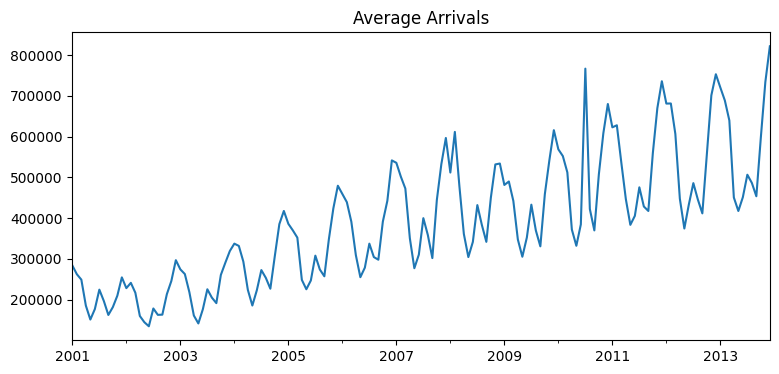

In [ ]:
arrivals_ts.plot(figsize=(9,4), title = "Average Arrivals")
plt.show()
#look at seasonality, trend, volatility

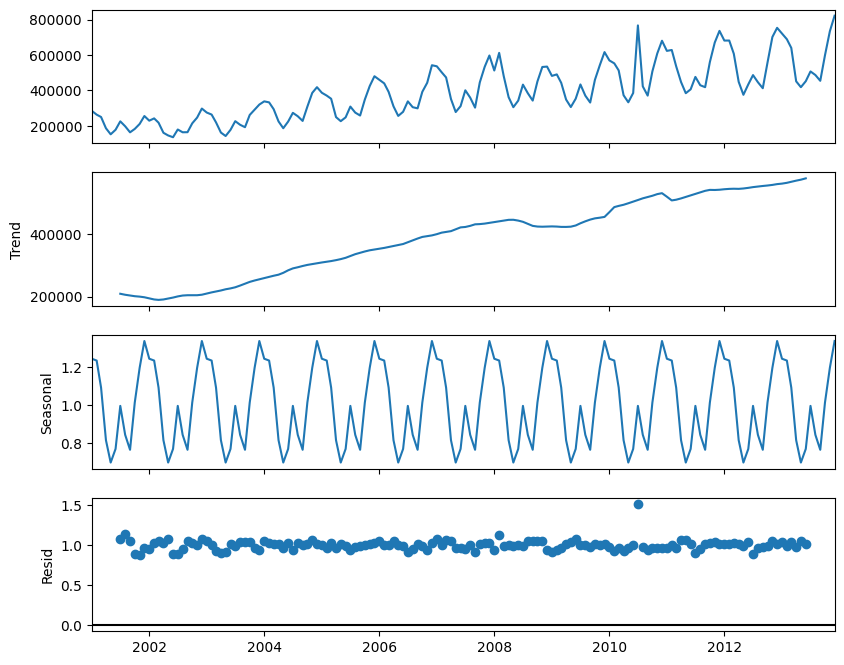

In [ ]:
#since there is volatility, do multiplicative decomposition
arrivals_ts_decomposed = seasonal_decompose (
    arrivals_ts,
    model = "multiplicative",
    period = 12
)
fig = arrivals_ts_decomposed.plot()
fig.set_size_inches(9,7)
plt.show()

In [ ]:
arrivals_ts_decomposed.resid["2010-04-01":"2010-10-01"]
#error in july 2010, 51% above standard

,resid
2010-04-01,0.925904
2010-05-01,0.957523
2010-06-01,0.994265
2010-07-01,1.514491
2010-08-01,0.974760
2010-09-01,0.934892
2010-10-01,0.958276


In [ ]:
#let us calculate the year over year increase in tourism
#compare the trend,  not raw data
trend_2013 = arrivals_ts_decomposed.trend["2013-01-01"]
trend_2012 = arrivals_ts_decomposed.trend["2012-01-01"]
percent_increase = (trend_2013-trend_2012)/trend_2012
percent_increase
#case says there is growth of 8%, it looks like its more so 3% increase

np.float64(0.033092500252839295)

In [ ]:
#let us better understand the tourism season in India
seasonal_cycle = arrivals_ts_decomposed.seasonal[0:12]
seasonal_cycle

,seasonal
2001-01-01,1.244611
2001-02-01,1.234903
2001-03-01,1.091992
2001-04-01,0.814207
2001-05-01,0.696174
2001-06-01,0.768143
2001-07-01,0.995468
2001-08-01,0.842688
2001-09-01,0.763540
2001-10-01,1.013417


In [ ]:
#we would like to know how much we staff for next year, therefore, forecast the number of tourist arrivals for next year (2014)
reg_df = pd.DataFrame(
    {"Arrivals":arrivals_ts.values,
     "trend": np.arange(1, len(arrivals_ts) +1),
     "month": arrivals_ts.index.month})
reg_df.head()

,Arrivals,trend,month
0,283750,1,1
1,262306,2,2
2,248965,3,3
3,185338,4,4
4,151098,5,5


In [ ]:
#let us create a linear time series regression
reg_model = ols("Arrivals ~ trend + C(month)", data = reg_df).fit()
reg_model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Arrivals   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     136.2
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           7.14e-72
Time:                        18:55:19   Log-Likelihood:                -1891.5
No. Observations:                 156   AIC:                             3809.
Df Residuals:                     143   BIC:                             3849.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        2.65e+05   1.43e+04     18.556      0.000    2.37e+05    2.93e+05
C(month)[T.2]  -5175.0728   1.83e+04     -0.283      0.778   -4.13e+04     3.1e+04
C(month)[T.3]  -5.802e+04   1.83e+04     -3.174      0.002   -9.42e+04   -2.19e+04
C(month)[T.4]  -1.643e+05   1.83e+04     -8.986      0.000      -2e+05   -1.28e+05
C(month)[T.5]  -2.106e+05   1.83e+04    -11.520      0.000   -2.47e+05   -1.74e+05
C(month)[T.6]  -1.813e+05   1.83e+04     -9.913      0.000   -2.17e+05   -1.45e+05
C(month)[T.7]  -9.715e+04   1.83e+04     -5.312      0.000   -1.33e+05    -6.1e+04
C(month)[T.8]   -1.58e+05   1.83e+04     -8.640      0.000   -1.94e+05   -1.22e+05
C(month)[T.9]  -1.888e+05   1.83e+04    -10.323      0.000   -2.25e+05   -1.53e+05
C(month)[T.10] -8.768e+04   1.83e+04     -4.792      0.000   -1.24e+05   -5.15e+04
C(month)[T.11] -1.052e+04   1.83e+04     -0.575      0.566   -4.67e+04    2.57e+04
C(month)[T.12]  4.282e+04   1.83e+04      2.339      0.021    6636.594     7.9e+04
trend           2787.8421     83.112     33.543      0.000    2623.556    2952.129
==============================================================================
Omnibus:                       71.001   Durbin-Watson:                   0.967
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              498.961
Skew:                           1.453   Prob(JB):                    4.49e-109
Kurtosis:                      11.265   Cond. No.                     1.13e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.13e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
#let us predict 2014 using this regression model
future_dates = pd.date_range(start = arrivals_ts.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")
future_dates

DatetimeIndex(['2014-01-01', '2014-02-01', '2014-03-01', '2014-04-01',
               '2014-05-01', '2014-06-01', '2014-07-01', '2014-08-01',
               '2014-09-01', '2014-10-01', '2014-11-01', '2014-12-01'],
              dtype='datetime64[ns]', freq='MS')

In [ ]:
pred = reg_model.get_prediction(future_df)
pred

In [ ]:
forecast_mean = pred.predicted_mean
ci = np.asarray(pred.conf_int())
forecast_mean

array([702671.11858974, 700283.88782051, 650227.73397436, 546747.88782051,
       503186.19551282, 535335.11858974, 622245.88782051, 564156.34935898,
       536126.11858974, 640084.65705128, 720032.96474359, 776156.19551282])

In [ ]:
forecast_table = pd.DataFrame ({
    "Month" : future_dates,
    "Forecast": forecast_mean,
    "Lower" : ci[:,0],
    "Upper" : ci[:,1],
})
forecast_table


,Month,Forecast,Lower,Upper
0,2014-01-01,702671.118590,673630.018249,731712.218930
1,2014-02-01,700283.887821,671242.787480,729324.988161
2,2014-03-01,650227.733974,621186.633634,679268.834315
3,2014-04-01,546747.887821,517706.787480,575788.988161
4,2014-05-01,503186.195513,474145.095172,532227.295853
5,2014-06-01,535335.118590,506294.018249,564376.218930
6,2014-07-01,622245.887821,593204.787480,651286.988161
7,2014-08-01,564156.349359,535115.249019,593197.449699
8,2014-09-01,536126.118590,507085.018249,565167.218930
9,2014-10-01,640084.657051,611043.556711,669125.757392


In [ ]:
#compare forecast to how many people you have in 2013 to see the amnt. of tourism increase
tourists_2013 = arrivals_ts["2013-01-1":"2013-12-01"]

In [ ]:
#compare the upper interval divided by tourists_2013
#we should increase our staff between april and october, up to 30%
ci[:,1]/tourists_2013

,0
2013-01-01,1.015814
2013-02-01,1.059189
2013-03-01,1.062138
2013-04-01,1.277884
2013-05-01,1.274939
2013-06-01,1.250770
2013-07-01,1.286043
2013-08-01,1.219723
2013-09-01,1.246067
2013-10-01,1.118762
